## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Payton Gergen

**Date:** 10/21/26

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

In [2]:
token_freq

[('new', 1365),
 ('date', 1202),
 ('get', 1052),
 ('please', 1022),
 ('enron', 927),
 ('like', 923),
 ('2002', 869),
 ('would', 806),
 ('one', 798),
 ('message', 795),
 ('call', 740),
 ('free', 691),
 ('software', 680),
 ('dear', 651),
 ('know', 644),
 ('email', 629),
 ('url:', 625),
 ('time', 609),
 ('start', 604),
 ('linguistics', 598),
 ('online', 591),
 ('need', 587),
 ('wrote:', 585),
 ('see', 554),
 ('conference', 553),
 ('language', 550),
 ('want', 548),
 ('empty', 546),
 ('hourahead', 526),
 ('list', 523),
 ('attached', 515),
 ('hello', 501),
 ('university', 500),
 ('2001', 489),
 ('information', 473),
 ('vince', 473),
 ('may', 461),
 ('good', 449),
 ('following', 448),
 ('hour', 446),
 ('2000', 442),
 ('business', 442),
 ('save', 423),
 ('first', 423),
 ('click', 423),
 ('best', 423),
 ('make', 421),
 ('com', 413),
 ('original', 410),
 ('offer', 405),
 ('meeting', 403),
 ('thanks', 397),
 ('mail', 395),
 ('use', 389),
 ('find', 386),
 ('papers', 383),
 ('http', 378),
 ('sent',

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

In [3]:
values = list(map(lambda x: x[1], token_freq)) # get the counts

(array([4.7744e+04, 5.2400e+02, 1.8900e+02, 7.6000e+01, 4.3000e+01,
        2.6000e+01, 2.6000e+01, 1.0000e+01, 1.1000e+01, 8.0000e+00,
        6.0000e+00, 6.0000e+00, 7.0000e+00, 3.0000e+00, 1.0000e+00,
        1.0000e+00, 3.0000e+00, 1.0000e+00, 1.0000e+00, 1.0000e+00,
        1.0000e+00, 1.0000e+00, 0.0000e+00, 0.0000e+00, 1.0000e+00,
        0.0000e+00, 0.0000e+00, 1.0000e+00]),
 array([1.00000000e+00, 4.97142857e+01, 9.84285714e+01, 1.47142857e+02,
        1.95857143e+02, 2.44571429e+02, 2.93285714e+02, 3.42000000e+02,
        3.90714286e+02, 4.39428571e+02, 4.88142857e+02, 5.36857143e+02,
        5.85571429e+02, 6.34285714e+02, 6.83000000e+02, 7.31714286e+02,
        7.80428571e+02, 8.29142857e+02, 8.77857143e+02, 9.26571429e+02,
        9.75285714e+02, 1.02400000e+03, 1.07271429e+03, 1.12142857e+03,
        1.17014286e+03, 1.21885714e+03, 1.26757143e+03, 1.31628571e+03,
        1.36500000e+03]),
 <BarContainer object of 28 artists>)

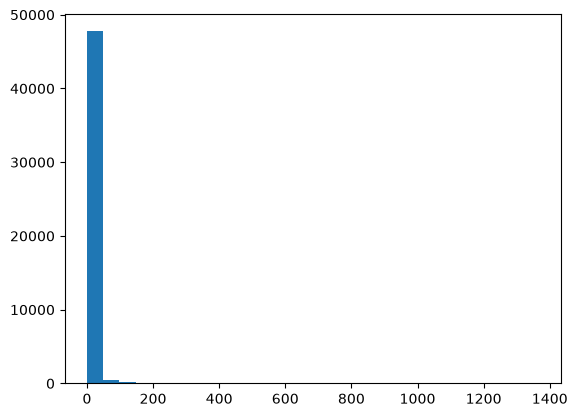

In [4]:
import matplotlib.pyplot as plt

plt.hist(values, bins = 28)

The historgam is very right skewed. Most of the words have fewer than 50 occurances. However, some of the words have as many as nearly 1400 occurrances.

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

In [8]:
import pandas as pd

phishing = pd.read_parquet("data/Phishing_clean.parquet", engine = "pyarrow")
phishing

,Email Type,new,date,get,please,enron,like,2002,would,one,...,ï¿½ï¿½,safety,yap,ypil,maintain,procedures,tip,elizabeth,leadership,italian
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18629,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
18630,0,0,0,0,1,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
18631,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
18632,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
from sklearn.model_selection import train_test_split

X = phishing.drop(columns=["Email Type"])
y = phishing["Email Type"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [12]:
from sklearn.linear_model import LinearRegression

model = LinearRegression(fit_intercept = False)
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",False
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2711,)","[ 0.06, 0.02, 0.08,...,-0.07, 0.03,-0.06]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2711,)","['new','date','get',...,'elizabeth','leadership','italian']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float,0
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2711
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2642)


In [14]:
r2_train = model.score(X_train, y_train)
r2_train

0.7000178781842663

In [16]:
r2_test = model.score(X_test, y_test)
r2_test

0.5525936922212535

R^2 is 0.700 for the training dataset and 0.553 for the test dataset.

In [20]:
coefs = pd.DataFrame({"Coefficient": model.coef_, "Word": model.feature_names_in_})

In [21]:
coefs.sort_values("Coefficient")

,Coefficient,Word
1504,-1.108790,background-image:
2182,-0.801324,reversing
2639,-0.607833,shopper
1511,-0.472607,burning
2559,-0.467514,april's
...,...,...
469,0.676861,utf
1637,0.677426,para
2701,0.837369,ï¿½ï¿½
2532,0.889854,xanaax


"aging", "background-image:", and "xanaax" have the largest coefficients, meaning they have the strongest effects on model prediction.

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

In [26]:
from sklearn.decomposition import PCA

X = phishing.drop(columns = "Email Type")
pca = PCA(n_components = 2).fit(X)
X_pca = pca.transform(X)

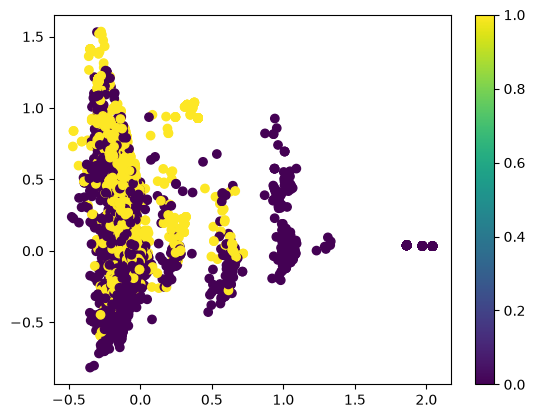

In [36]:
y = phishing["Email Type"]
plt.scatter(X_pca[:,0], X_pca[:,1], c = y)
plt.colorbar()

Scam emails have lower values on PC1, ranging from about -0.5 to about 0.6. Only non-scam emails have values on PC1 above 0.8.

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [40]:
pca_2 = PCA(n_components = 2610).fit(X_train)
X_pca_2 = pca_2.transform(X_train)

In [41]:
reg = LinearRegression()
reg.fit(X_pca_2, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2610,)","[-0.25, 0.51, 0.15,...,-0.39,-0.02,-0.22]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.3888
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2610
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2610)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](2610,)","[37.52,32.9 ,31.52,..., 1.1 , 1.07, 1.05]"


In [44]:
r2_train_2 = reg.score(X_pca_2, y_train)
r2_train_2

0.7679413296276346

In [45]:
X_test_pca = pca_2.transform(X_test)

r2_test_2 = reg.score(X_test_pca, y_test)
r2_test_2

0.6529441933068715

This approach performs better than linear regression. The R^2 values for both the training and test datasets are higher.

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

Using the principal components to run regression reduces the amount of noise due to the size of the dataset. There is overlap in certain features. Using principal components thus leads to better fit models.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]